<a href="https://colab.research.google.com/github/GabyPaolaING/Machine-Learning/blob/main/P3P1_Regresi%C3%B3n_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Intercepto (Peso inicial estimado): 84.68 kg
Coeficiente Dias_Transcurridos (beta_1): -0.0314 kg/día
Coeficiente Carga_Semanal_Km (beta_2): -0.0203 kg/km

R² (Varianza explicada): 0.914
MAE (Error promedio): 0.48 kg
RMSE (Error cuadrático raíz): 0.62 kg

Peso estimado para el escenario nuevo (150 días, 140 km): 77.12 kg


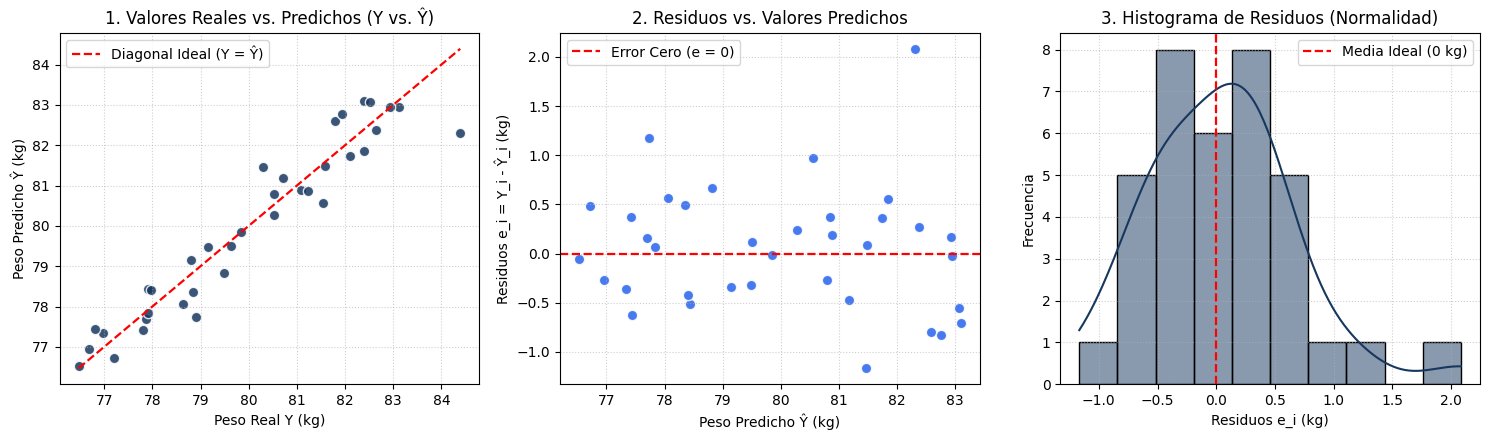

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

np.random.seed(42)
n_samples = 180
dias_transcurridos = np.arange(1, n_samples + 1)
carga_semanal_km = np.clip(65 + 0.35 * dias_transcurridos + np.random.normal(0, 18, n_samples), 30, 210)
peso_kg = 84.50 - 0.032 * dias_transcurridos - 0.018 * carga_semanal_km + np.random.normal(0, 0.55, n_samples)

df_integrado = pd.DataFrame({
    'Dias_Transcurridos': dias_transcurridos,
    'Carga_Semanal_Km': np.round(carga_semanal_km, 1),
    'Peso(Kg)': np.round(peso_kg, 2)
})

X = df_integrado[['Dias_Transcurridos', 'Carga_Semanal_Km']]
y = df_integrado['Peso(Kg)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

beta_0 = modelo_lineal.intercept_
betas = modelo_lineal.coef_

print(f"Intercepto (Peso inicial estimado): {beta_0:.2f} kg")
print(f"Coeficiente Dias_Transcurridos (beta_1): {betas[0]:.4f} kg/día")
print(f"Coeficiente Carga_Semanal_Km (beta_2): {betas[1]:.4f} kg/km")

y_pred = modelo_lineal.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nR² (Varianza explicada): {r2:.3f}")
print(f"MAE (Error promedio): {mae:.2f} kg")
print(f"RMSE (Error cuadrático raíz): {rmse:.2f} kg")

escenario_nuevo = pd.DataFrame({'Dias_Transcurridos': [150], 'Carga_Semanal_Km': [140]})
peso_estimado = modelo_lineal.predict(escenario_nuevo)
print(f"\nPeso estimado para el escenario nuevo (150 días, 140 km): {peso_estimado[0]:.2f} kg")

residuos = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(y_test, y_pred, color='#17375E', alpha=0.85, edgecolors='white', s=55)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=1.6, label='Diagonal Ideal (Y = Ŷ)')
axes[0].set_title('1. Valores Reales vs. Predichos (Y vs. Ŷ)')
axes[0].set_xlabel('Peso Real Y (kg)')
axes[0].set_ylabel('Peso Predicho Ŷ (kg)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].scatter(y_pred, residuos, color='#2563EB', alpha=0.85, edgecolors='white', s=55)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.6, label='Error Cero (e = 0)')
axes[1].set_title('2. Residuos vs. Valores Predichos')
axes[1].set_xlabel('Peso Predicho Ŷ (kg)')
axes[1].set_ylabel('Residuos e_i = Y_i - Ŷ_i (kg)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

sns.histplot(residuos, kde=True, bins=10, color='#17375E', ax=axes[2])
axes[2].axvline(0, color='red', linestyle='--', linewidth=1.6, label='Media Ideal (0 kg)')
axes[2].set_title('3. Histograma de Residuos (Normalidad)')
axes[2].set_xlabel('Residuos e_i (kg)')
axes[2].set_ylabel('Frecuencia')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()